In [1]:
import os
import sys
import joblib
import glob
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.constants import Configs

RESULTS_DIR = Configs._wrist_only_loso_results_cache_dir

In [2]:
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR

if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
def load_all_fold_results(results_dir, model, representation, phase):
    rows = []
    blind_y_true = []
    blind_y_pred = []

    for file in glob.glob(os.path.join(results_dir, "*.pkl")):
        obj = joblib.load(file)

        # Recover metadata from the filename:
        # wrist_only_loso_results_{model}_{representation}_{movement}.pkl
        stem = Path(file).stem.replace("wrist_only_loso_results_", "")
        model, representation, phase = stem.rsplit("_", 2)

        if model == model and representation == representation and phase == phase:
            return obj

    raise FileNotFoundError(f"No results found for model '{model}' and representation '{representation}' and phase '{phase}' in {results_dir}.")

In [4]:
loso_results = load_all_fold_results(RESULTS_DIR, "LOF", "ShapeBased", "Pick")

In [5]:
grouped_keys = df.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

In [6]:
unique_trials = metadata_df[['sub', 'repID']].drop_duplicates().reset_index(drop=True)

# 2. Extract predictions from your LOSO output dictionary
y_true = loso_results['Blind_Y_True']
y_pred = loso_results['Blind_Y_Pred']

unique_trials['y_true'] = y_true
unique_trials['y_pred'] = y_pred

# 3. Find one specific trial for each case
tn_trial = unique_trials[(unique_trials['y_true'] == 0) & (unique_trials['y_pred'] == 0)].iloc[0]
fp_trial = unique_trials[(unique_trials['y_true'] == 0) & (unique_trials['y_pred'] == 1)].iloc[0]
fn_trial = unique_trials[(unique_trials['y_true'] == 1) & (unique_trials['y_pred'] == 0)].iloc[0]

print(f"TN found at Sub: {tn_trial['sub']}, Rep: {tn_trial['repID']}")
print(f"FP found at Sub: {fp_trial['sub']}, Rep: {fp_trial['repID']}")
print(f"FN found at Sub: {fn_trial['sub']}, Rep: {fn_trial['repID']}")

TN found at Sub: 6, Rep: 1
FP found at Sub: 4, Rep: 5
FN found at Sub: 10, Rep: 1


In [7]:
# Set style for academic Q1 papers
plt.rcParams.update({'font.size': 11, 'font.family': 'serif'})

def plot_qualitative_errors(tn_data, fp_data, fn_data, feature_name='vel'):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
    
    datasets = [
        (tn_data, axes[0], 'True Negative (Nominal)'),
        (fp_data, axes[1], 'False Positive (Tactile Jitter)'),
        (fn_data, axes[2], 'False Negative (Smooth Spatial Error)')
    ]
    
    for data, ax, base_title in datasets:
        sub_id = data['sub'].iloc[0]
        rep_id = data['repID'].iloc[0]
        
        unique_movs = data['movID'].unique()
        colors = sns.color_palette("husl", len(unique_movs))
        
        for mov_id, color in zip(unique_movs, colors):
            subset = data[data['movID'] == mov_id]
            ax.plot(
                subset['step'], 
                subset[feature_name], 
                color=color, 
                linewidth=2, 
                label=f'movID: {mov_id}'
            )
            
        full_title = f"{base_title}\nSub: {sub_id} | Rep: {rep_id}"
        ax.set_title(full_title, fontweight='bold')
        ax.set_ylabel(feature_name)
        ax.set_xlabel('Step')
        ax.grid(True, linestyle='--', alpha=0.6)
        
        ax.legend(fontsize=8, loc='upper right', bbox_to_anchor=(1, 1))
        
    fig.tight_layout()
    plt.show()

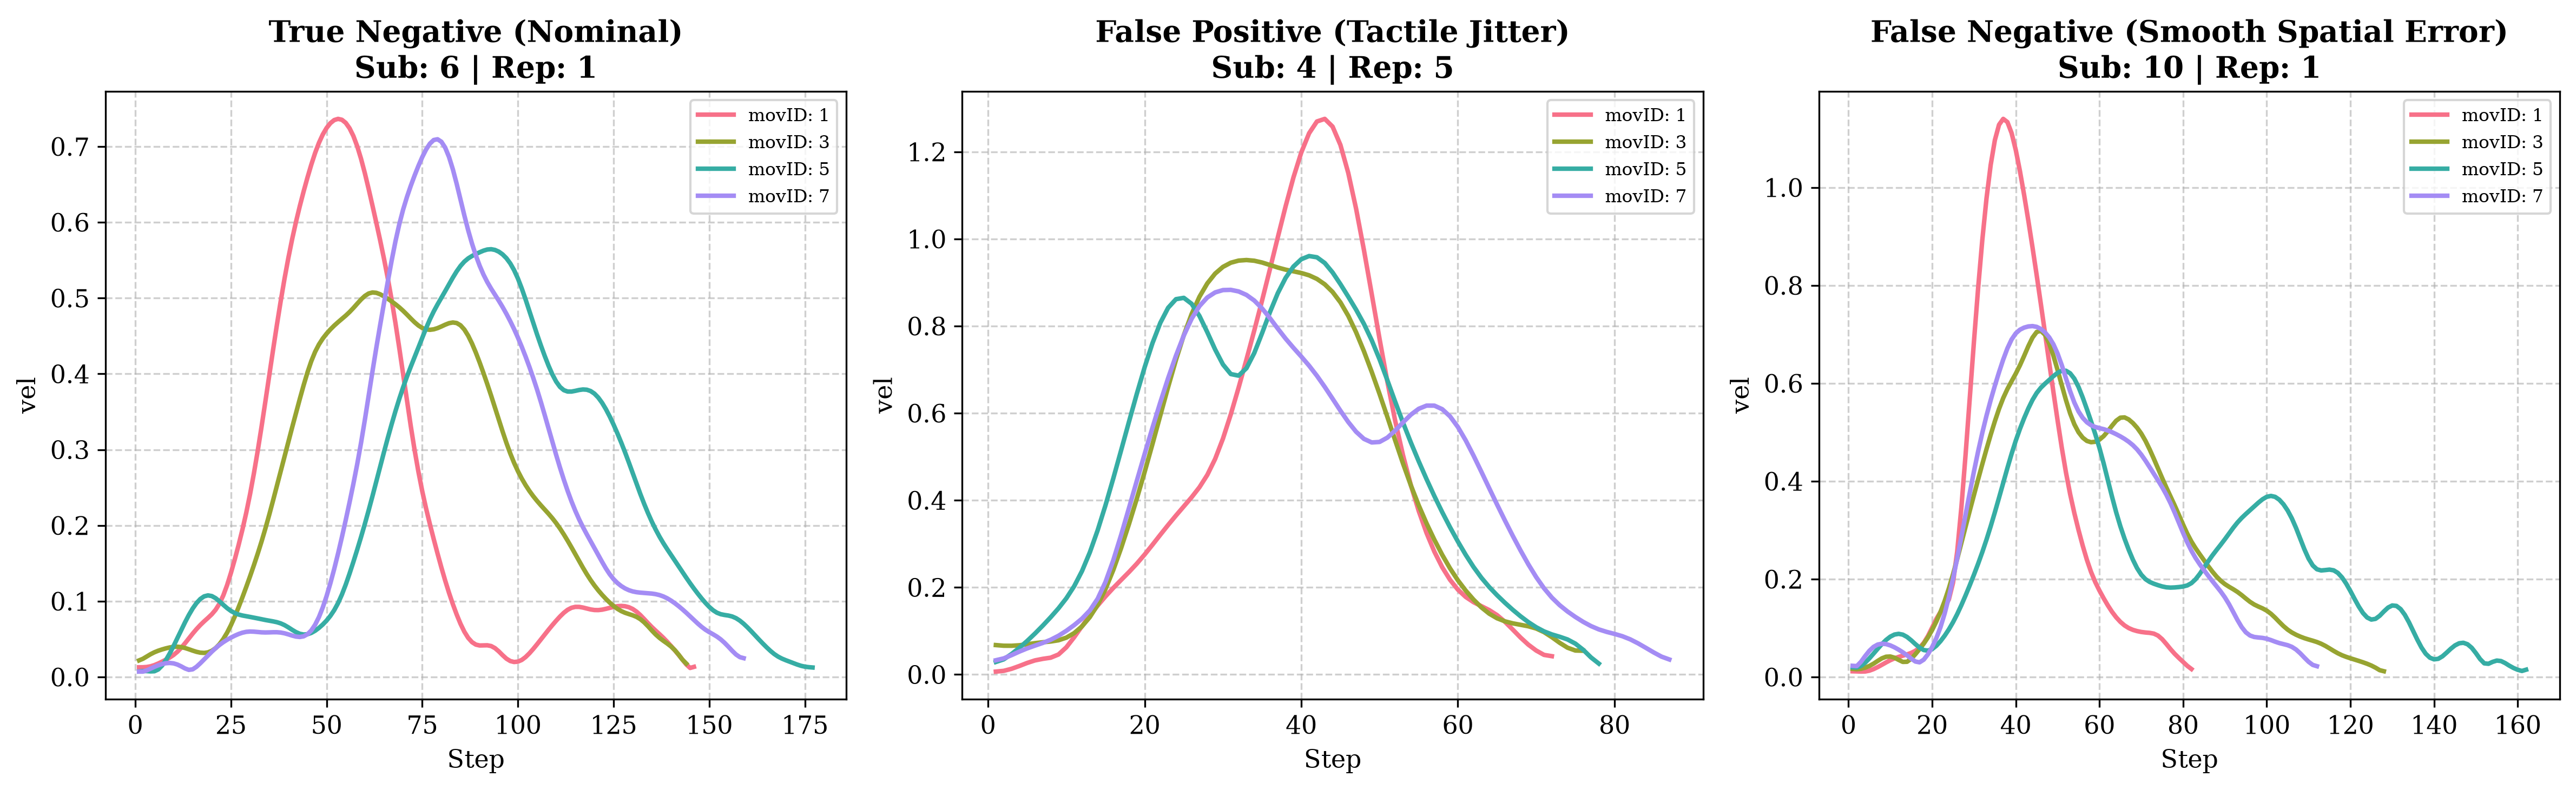

In [8]:
# Extract full time-series data for the specific trials
# Ensure we isolate the 'Pick' phase as loaded in your LOSO results
tn_series = df[(df['sub'] == tn_trial['sub']) & (df['repID'] == tn_trial['repID']) & (df['movLabel'] == 'Pick')]
fp_series = df[(df['sub'] == fp_trial['sub']) & (df['repID'] == fp_trial['repID']) & (df['movLabel'] == 'Pick')]
fn_series = df[(df['sub'] == fn_trial['sub']) & (df['repID'] == fn_trial['repID']) & (df['movLabel'] == 'Pick')]

plot_qualitative_errors(
    tn_data=tn_series,
    fp_data=fp_series,
    fn_data=fn_series,
    feature_name='vel' 
)

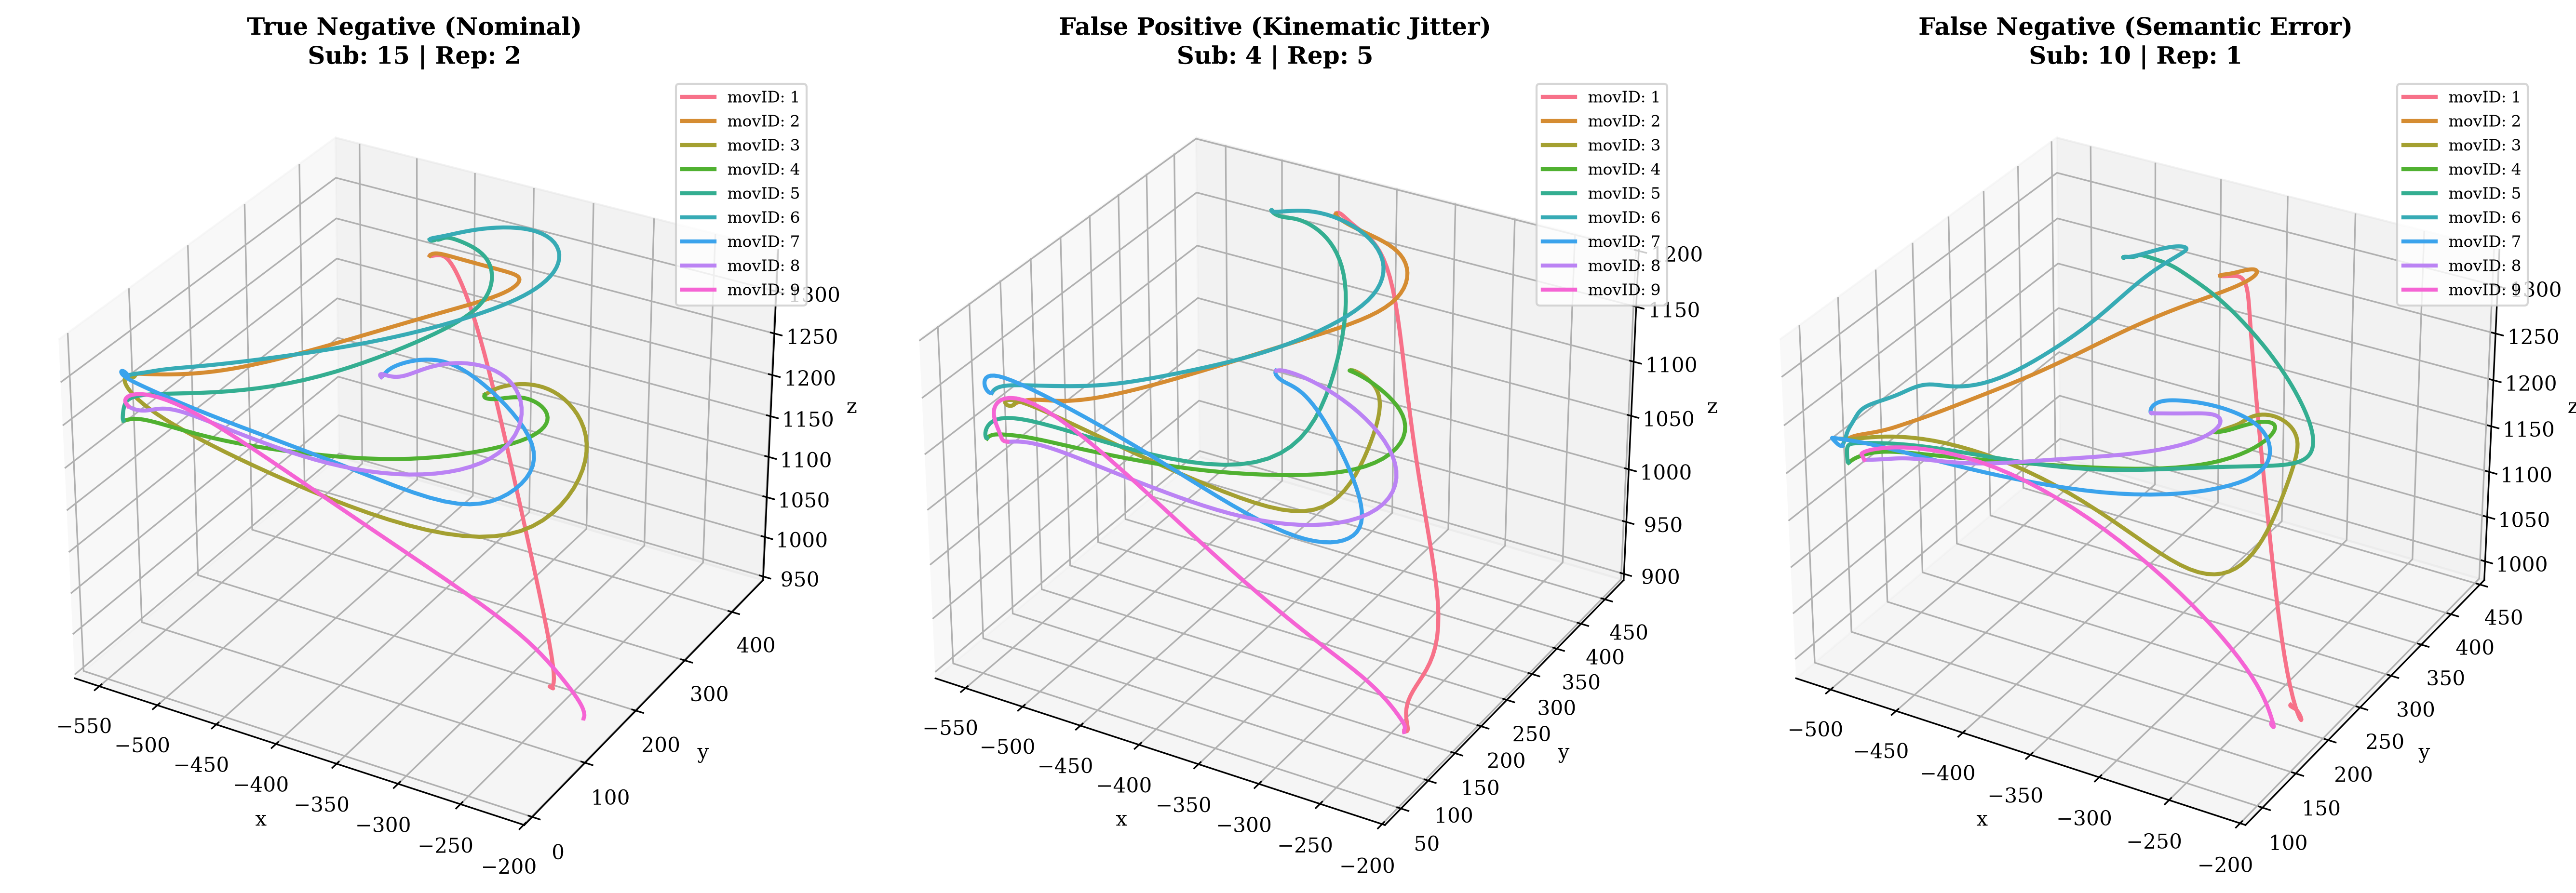

In [9]:
def get_trial_data(df, trials_df, condition_true, condition_pred, n_samples=1):
    filtered_trials = trials_df[(trials_df['y_true'] == condition_true) & 
                                (trials_df['y_pred'] == condition_pred)]
    
    if filtered_trials.empty:
        return pd.DataFrame()
        
    sampled_trials = filtered_trials.sample(n=min(n_samples, len(filtered_trials)))
    
    merged_data = pd.DataFrame()
    for _, trial in sampled_trials.iterrows():
        trial_data = df[(df['sub'] == trial['sub']) & (df['repID'] == trial['repID'])]
        merged_data = pd.concat([merged_data, trial_data])
        
    return merged_data

def plot_qualitative_3d_errors(tn_data, fp_data, fn_data, x_col='X', y_col='Y', z_col='Z'):
    plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
    fig = plt.figure(figsize=(18, 6), dpi=300)
    
    datasets = [
        (tn_data, 1, 'True Negative (Nominal)'),
        (fp_data, 2, 'False Positive (Kinematic Jitter)'),
        (fn_data, 3, 'False Negative (Semantic Error)')
    ]
    
    for data, pos, title in datasets:
        if data.empty:
            continue
            
        ax = fig.add_subplot(1, 3, pos, projection='3d')
        sub_id = data['sub'].iloc[0]
        rep_id = data['repID'].iloc[0]
        
        unique_movs = data['movID'].unique()
        colors = sns.color_palette("husl", len(unique_movs))
        
        for mov_id, color in zip(unique_movs, colors):
            subset = data[data['movID'] == mov_id]
            ax.plot(
                subset[x_col], 
                subset[y_col], 
                subset[z_col], 
                color=color, 
                linewidth=2, 
                label=f'movID: {mov_id}'
            )
            
        ax.set_title(f"{title}\nSub: {sub_id} | Rep: {rep_id}", fontweight='bold')
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_zlabel(z_col)
        ax.legend(fontsize=8, loc='best')
        
    plt.tight_layout()
    plt.show()

tn_sample = get_trial_data(df, unique_trials, condition_true=0, condition_pred=0)
fp_sample = get_trial_data(df, unique_trials, condition_true=0, condition_pred=1)
fn_sample = get_trial_data(df, unique_trials, condition_true=1, condition_pred=0)

plot_qualitative_3d_errors(tn_sample, fp_sample, fn_sample, x_col='x', y_col='y', z_col='z')